# Pre-processing of the PLC Data (Siemens + Beckhoff)

**Goal:** Prepare the two cleaned datasets so they can be merged and used for stop detection and K-Means. Every step answers one hypothesis from `HYPOTHESES.md`.

**Input:** `siemens_cleaned.csv`, `beckhoff_cleaned.csv` (`data/processed/`)
**Output (at the end of this notebook):** `merged.csv` (`data/processed/`)

Run the cells from top to bottom (Run All).

## Load both cleaned datasets and check the time overlap (H2, part a)

### Summary

Both cleaned files are loaded. For each PLC the first time, last time, duration and median logging interval are printed. The overlap of the two recordings is calculated, because only the overlapping part can be merged. If there is no overlap, the merge is impossible.

In [2]:
%pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----------------------------------- ---- 71.7/80.3 kB ? eta -:--:--
     -------------------------------------- 80.3/80.3 kB 752.9 kB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/142.6 kB ? eta -:--:--
     ----------------------------------- -- 133.1/142.6 kB 7.7 MB/s eta 0:00:01
     -------------------------------------- 142.6/142.6 kB 1.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB 9.9 MB/s eta 0:00:01
   -- ------------------------------------- 0.6/9.3 MB 5.7 MB/s eta 0:00:02
   --- ------------------------------------ 0.9/9.3 MB 5.3 MB/s eta 0:00:02
   ---- ----------------------------------- 1.1/9.3 MB 5.1 MB/s eta 0:00:02
   ------ --------------------------------- 1.5/9.3 MB 5.0 MB/s eta 0:00:02
   ------- ------------------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


======================================== SIEMENS ========================================
Shape: (6282, 143)
First time: 2019-09-26 18:21:14.515000+00:00
Last time:  2019-09-26 18:29:40.213000+00:00
Duration (s): 505.698
Median interval (ms): 76.0
======================================== BECKHOFF ========================================
Shape: (5197, 54)
First time: 2019-09-26 18:21:14.925000+00:00
Last time:  2019-09-26 18:29:40.319000+00:00
Duration (s): 505.394
Median interval (ms): 93.0

======================================== OVERLAP ========================================
Overlap start: 2019-09-26 18:21:14.925000+00:00
Overlap end:   2019-09-26 18:29:40.213000+00:00
Overlap duration (s): 505.288


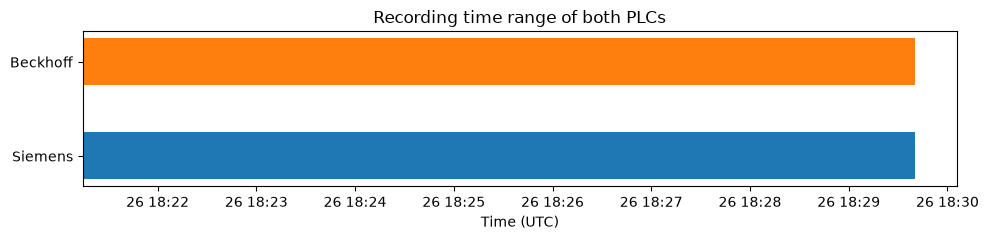

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent            # notebook lives in notebooks/
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

siemens_clean = pd.read_csv(PROCESSED_DATA_DIR / "siemens_cleaned.csv")
beckhoff_clean = pd.read_csv(PROCESSED_DATA_DIR / "beckhoff_cleaned.csv")

# Time range of each PLC
for name, df in [("SIEMENS", siemens_clean), ("BECKHOFF", beckhoff_clean)]:
    ts = df["timestamp"]
    print("=" * 40, name, "=" * 40)
    print("Shape:", df.shape)
    print("First time:", pd.to_datetime(ts.iloc[0], unit="ms", utc=True))
    print("Last time: ", pd.to_datetime(ts.iloc[-1], unit="ms", utc=True))
    print("Duration (s):", (ts.iloc[-1] - ts.iloc[0]) / 1000)
    print("Median interval (ms):", ts.diff().median())

# Overlap of the two recordings
overlap_start = max(siemens_clean["timestamp"].iloc[0], beckhoff_clean["timestamp"].iloc[0])
overlap_end = min(siemens_clean["timestamp"].iloc[-1], beckhoff_clean["timestamp"].iloc[-1])
overlap_seconds = (overlap_end - overlap_start) / 1000

print("\n" + "=" * 40, "OVERLAP", "=" * 40)
print("Overlap start:", pd.to_datetime(overlap_start, unit="ms", utc=True))
print("Overlap end:  ", pd.to_datetime(overlap_end, unit="ms", utc=True))
print("Overlap duration (s):", overlap_seconds)

# Plot: both recordings on one time axis
fig, ax = plt.subplots(figsize=(10, 2.5))
for row, (name, df) in enumerate([("Siemens", siemens_clean), ("Beckhoff", beckhoff_clean)]):
    start = pd.to_datetime(df["timestamp"].iloc[0], unit="ms", utc=True)
    end = pd.to_datetime(df["timestamp"].iloc[-1], unit="ms", utc=True)
    ax.barh(row, end - start, left=start, height=0.5, label=name)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Siemens", "Beckhoff"])
ax.set_xlabel("Time (UTC)")
ax.set_title("Recording time range of both PLCs")
plt.tight_layout()
plt.show()

## Choose the common time grid (H1)

### Summary

The two PLCs log at different, irregular intervals, so both must be put on one regular time grid before merging. If the grid is too coarse, a short ON pulse that starts and ends between two grid points disappears. For each PLC and for grid sizes of 20, 50, 100 and 200 ms, the boolean signals are resampled (each grid point takes the last known value, no interpolation), and the ON/OFF changes before and after are counted. The loss in percent shows how much information each grid destroys.


Siemens: 125 boolean signals, 2023.0 changes in the raw data
Beckhoff: 50 boolean signals, 4438.0 changes in the raw data

Lost signal changes (%):
         Siemens  Beckhoff
grid_ms                   
20          0.00      0.00
50          0.00      0.00
100         7.02      4.01
200        18.49     33.66


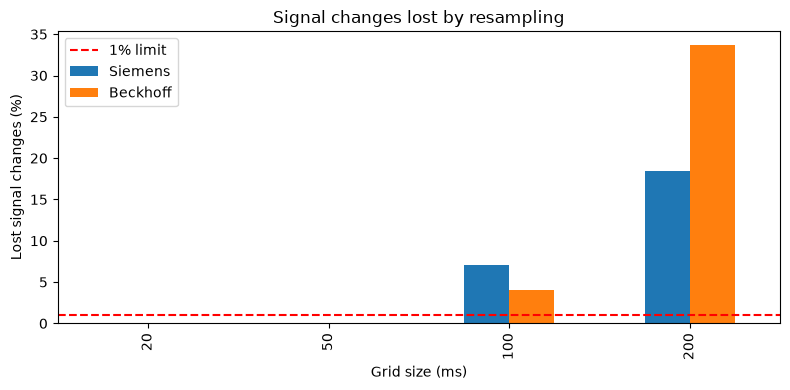

Coarsest grid with loss < 1% in both PLCs: 50


In [4]:
import numpy as np

grid_sizes = [20, 50, 100, 200]          # candidate grid sizes in ms
loss_table = pd.DataFrame(index=grid_sizes, columns=["Siemens", "Beckhoff"], dtype=float)
loss_table.index.name = "grid_ms"

for name, df in [("Siemens", siemens_clean), ("Beckhoff", beckhoff_clean)]:
    # only boolean signals: count their ON/OFF changes
    signals = df.drop(columns="timestamp").select_dtypes(include="bool")
    edges_raw = signals.astype(int).diff().abs().sum().sum()
    ts = df["timestamp"].values

    for step in grid_sizes:
        grid = np.arange(ts[0], ts[-1], step)
        # last known value at each grid point (forward fill, no interpolation)
        position = np.searchsorted(ts, grid, side="right") - 1
        edges_grid = signals.iloc[position].astype(int).diff().abs().sum().sum()
        loss_table.loc[step, name] = (edges_raw - edges_grid) / edges_raw * 100

    print(f"{name}: {signals.shape[1]} boolean signals, {edges_raw} changes in the raw data")

print("\nLost signal changes (%):")
print(loss_table.round(2).to_string())

# Plot
ax = loss_table.plot(kind="bar", figsize=(8, 4))
ax.axhline(1, color="red", linestyle="--", label="1% limit")
ax.set_xlabel("Grid size (ms)")
ax.set_ylabel("Lost signal changes (%)")
ax.set_title("Signal changes lost by resampling")
ax.legend()
plt.tight_layout()
plt.show()

# Decision rule: coarsest grid with loss < 1% in both PLCs
accepted = loss_table[(loss_table < 1).all(axis=1)]
print("Coarsest grid with loss < 1% in both PLCs:",
      accepted.index.max() if not accepted.empty else "none")